### Time Series Analysis of Network Utilization for Distributed Scientific Workflows
#### Yingxin Deng
#### 2026/09/15

### This week's task: TCN Baseline for SoCal Daily XCache Data

Create a small Temporal Convolutional Network (TCN) baseline model: 
1. Use only SoCal Data
2. Use the full time range (2020-05-31 to 2024-03-31, total 1401 days)
2. Use the previous 28 days of six XCache variables to predict the next day. 
4. Test RMSE is reported in original units: requests for count variables and TB for size variables.


In [12]:
from pathlib import Path
import copy
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch version: {torch.__version__}')
print(f'Device: {device}')

PyTorch version: 2.2.2
Device: cpu


In [13]:
# Load SoCal daily multivariate data and convert data volumes from bytes to TB.
data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df')]
data_dir = next((path for path in data_dirs if path.exists()), None)
if data_dir is None:
    raise FileNotFoundError('Please unzip the XCache data archive before running this notebook.')

df = pd.read_pickle(data_dir / 'socal-2006-2403-daily-ml').copy()
size_columns = ['access_size', 'hit_size', 'miss_size']
df[size_columns] = df[size_columns] / (1000 ** 4)
feature_names = list(df.columns)
print(f'Data shape: {df.shape}')
print(f'Time range: {df.index.min().date()} to {df.index.max().date()}')
display(df.head())

Data shape: (1401, 6)
Time range: 2020-05-31 to 2024-03-31


,access_count,access_size,hit_count,hit_size,miss_count,miss_size
data_start_time_datetime,,,,,,
2020-05-31,9615,7.247672,5648,4.306678,3967,2.940994
2020-06-01,37391,23.700100,22909,14.073827,14482,9.626272
2020-06-02,61088,34.787786,25539,11.936270,35549,22.851516
2020-06-03,35953,26.438742,23689,18.058082,12264,8.380659
2020-06-04,44218,40.089986,31600,26.688669,12618,13.401317


In [14]:
# Experiment: previous 28 days predict the next day.
LOOKBACK, HORIZON = 28, 1
TRAIN_FRACTION, VALIDATION_FRACTION = 0.70, 0.15
values = df.to_numpy(dtype=np.float32)
n_observations = len(values)
train_end = int(n_observations * TRAIN_FRACTION)
validation_end = int(n_observations * (TRAIN_FRACTION + VALIDATION_FRACTION))

# Fit the scaler on the training period only, preventing test-data leakage.
scaler = StandardScaler().fit(values[:train_end])
scaled_values = scaler.transform(values)

def make_windows(data, index, lookback, horizon):
    X, y, dates = [], [], []
    for target_start in range(lookback, len(data) - horizon + 1):
        X.append(data[target_start - lookback:target_start])
        y.append(data[target_start:target_start + horizon])
        dates.append(index[target_start])
    return np.array(X), np.array(y), pd.DatetimeIndex(dates)

X_all, y_all, target_dates = make_windows(scaled_values, df.index, LOOKBACK, HORIZON)
target_positions = np.arange(LOOKBACK, n_observations - HORIZON + 1)
train_mask = target_positions < train_end
validation_mask = (target_positions >= train_end) & (target_positions < validation_end)
test_mask = target_positions >= validation_end
X_train, y_train = X_all[train_mask], y_all[train_mask]
X_validation, y_validation = X_all[validation_mask], y_all[validation_mask]
X_test, y_test, test_dates = X_all[test_mask], y_all[test_mask], target_dates[test_mask]
print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_validation.shape, y_validation.shape)
print('Test:', X_test.shape, y_test.shape)

Train: (952, 28, 6) (952, 1, 6)
Validation: (210, 28, 6) (210, 1, 6)
Test: (211, 28, 6) (211, 1, 6)


In [15]:
class Chomp1d(nn.Module):
    def __init__(self, size):
        super().__init__()
        self.size = size

    def forward(self, x):
        return x[:, :, :-self.size].contiguous() if self.size > 0 else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout):
        super().__init__()
        padding = (kernel_size - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(out_channels, out_channels, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding), nn.ReLU(), nn.Dropout(dropout)
        )
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        return torch.relu(self.net(x) + self.residual(x))

class TCNForecaster(nn.Module):
    def __init__(self, input_size, output_size, horizon, channels=(32, 32, 32), kernel_size=3, dropout=0.1):
        super().__init__()
        blocks, in_channels = [], input_size
        for level, out_channels in enumerate(channels):
            blocks.append(TemporalBlock(in_channels, out_channels, kernel_size, 2 ** level, dropout))
            in_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(channels[-1], horizon * output_size)
        self.horizon, self.output_size = horizon, output_size

    def forward(self, x):
        hidden = self.tcn(x)[:, :, -1]
        return self.output(hidden).view(-1, self.horizon, self.output_size)

model = TCNForecaster(len(feature_names), len(feature_names), HORIZON).to(device)
print(model)

TCNForecaster(
  (tcn): Sequential(
    (0): TemporalBlock(
      (net): Sequential(
        (0): Conv1d(6, 32, kernel_size=(3,), stride=(1,), padding=(2,))
        (1): Chomp1d()
        (2): ReLU()
        (3): Dropout(p=0.1, inplace=False)
        (4): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(2,))
        (5): Chomp1d()
        (6): ReLU()
        (7): Dropout(p=0.1, inplace=False)
      )
      (residual): Conv1d(6, 32, kernel_size=(1,), stride=(1,))
    )
    (1): TemporalBlock(
      (net): Sequential(
        (0): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
        (1): Chomp1d()
        (2): ReLU()
        (3): Dropout(p=0.1, inplace=False)
        (4): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
        (5): Chomp1d()
        (6): ReLU()
        (7): Dropout(p=0.1, inplace=False)
      )
      (residual): Identity()
    )
    (2): TemporalBlock(
      (net): Sequential(
        (0): Conv1d(32, 32, kern

Epoch 01: train MSE=0.8008, validation MSE=1.8765
Epoch 10: train MSE=0.4501, validation MSE=1.1902
Early stopping at epoch 19


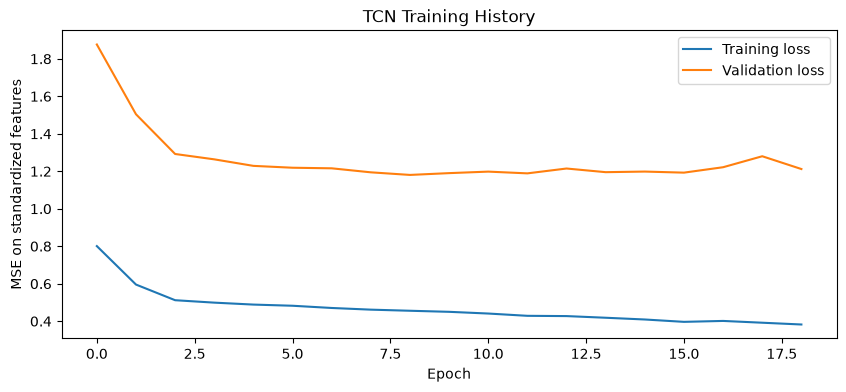

In [16]:
def to_loader(X, y, shuffle=False):
    X_tensor = torch.tensor(X.transpose(0, 2, 1), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)
    return DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=32, shuffle=shuffle)

train_loader = to_loader(X_train, y_train, shuffle=True)
validation_loader = to_loader(X_validation, y_validation)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
MAX_EPOCHS, PATIENCE = 60, 10
best_validation_loss, best_state, no_improvement = float('inf'), None, 0
history = {'train': [], 'validation': []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_losses = []
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        validation_losses = [criterion(model(X_batch.to(device)), y_batch.to(device)).item()
                             for X_batch, y_batch in validation_loader]
    train_loss, validation_loss = np.mean(train_losses), np.mean(validation_losses)
    history['train'].append(train_loss)
    history['validation'].append(validation_loss)

    if validation_loss < best_validation_loss:
        best_validation_loss, best_state, no_improvement = validation_loss, copy.deepcopy(model.state_dict()), 0
    else:
        no_improvement += 1
        if no_improvement >= PATIENCE:
            print(f'Early stopping at epoch {epoch}')
            break
    if epoch == 1 or epoch % 10 == 0:
        print(f'Epoch {epoch:02d}: train MSE={train_loss:.4f}, validation MSE={validation_loss:.4f}')

model.load_state_dict(best_state)
plt.figure(figsize=(10, 4))
plt.plot(history['train'], label='Training loss')
plt.plot(history['validation'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('MSE on standardized features')
plt.title('TCN Training History')
plt.legend()
plt.show()

,RMSE,Unit
access_count,13228.707571,requests
access_size,31.123640,TB
hit_count,11364.343184,requests
hit_size,30.035986,TB
miss_count,2590.031177,requests
miss_size,3.655213,TB


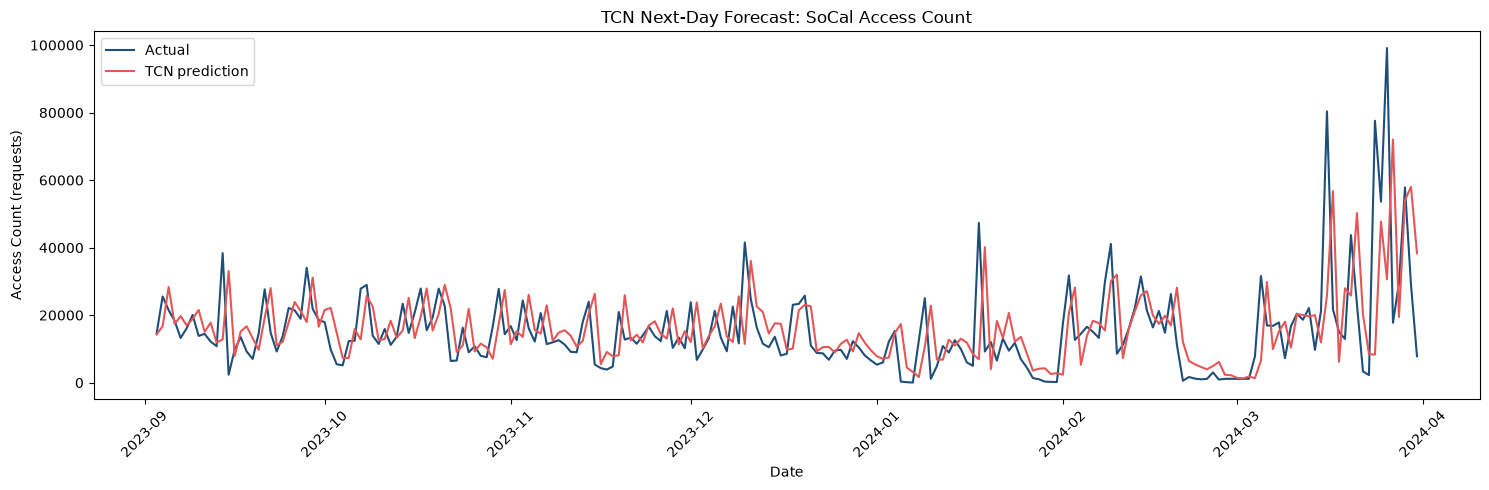

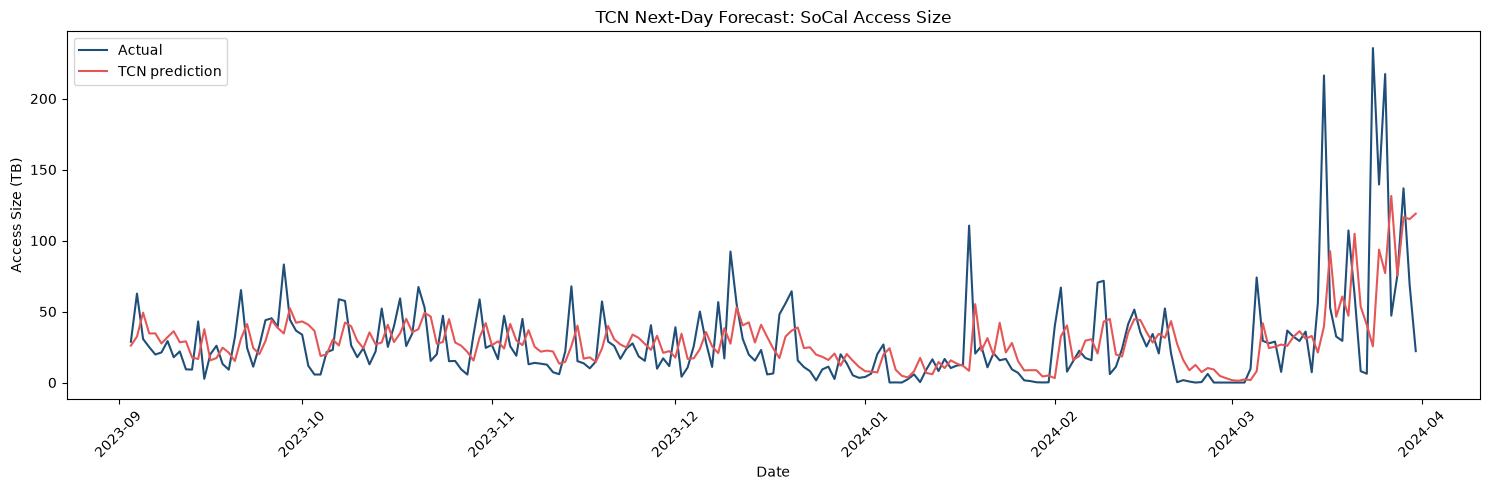

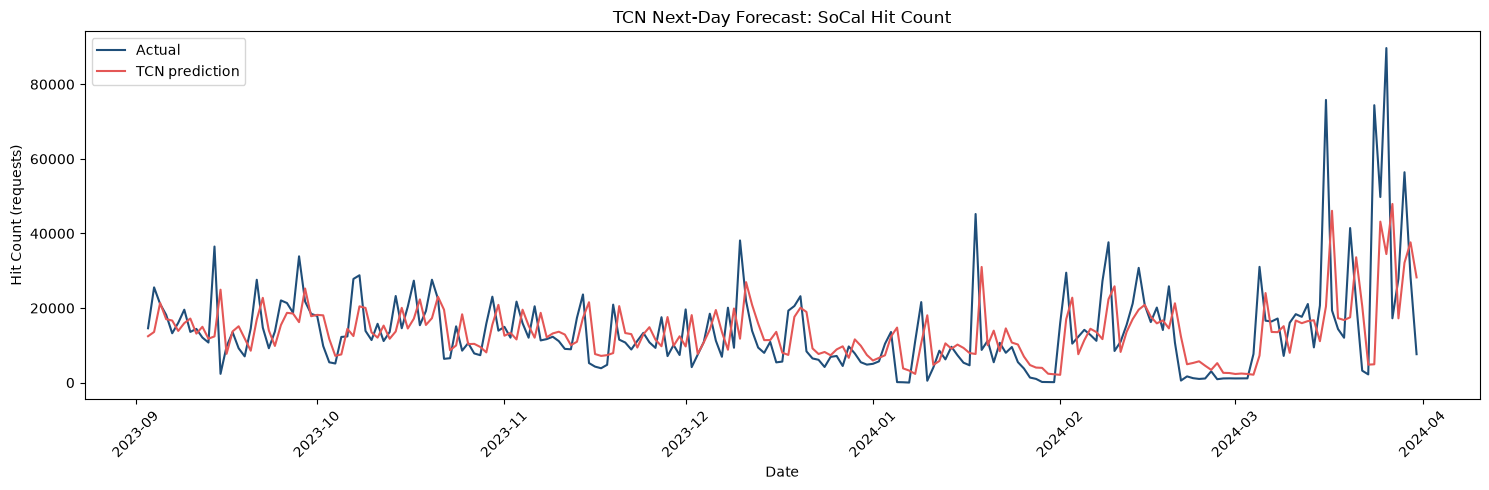

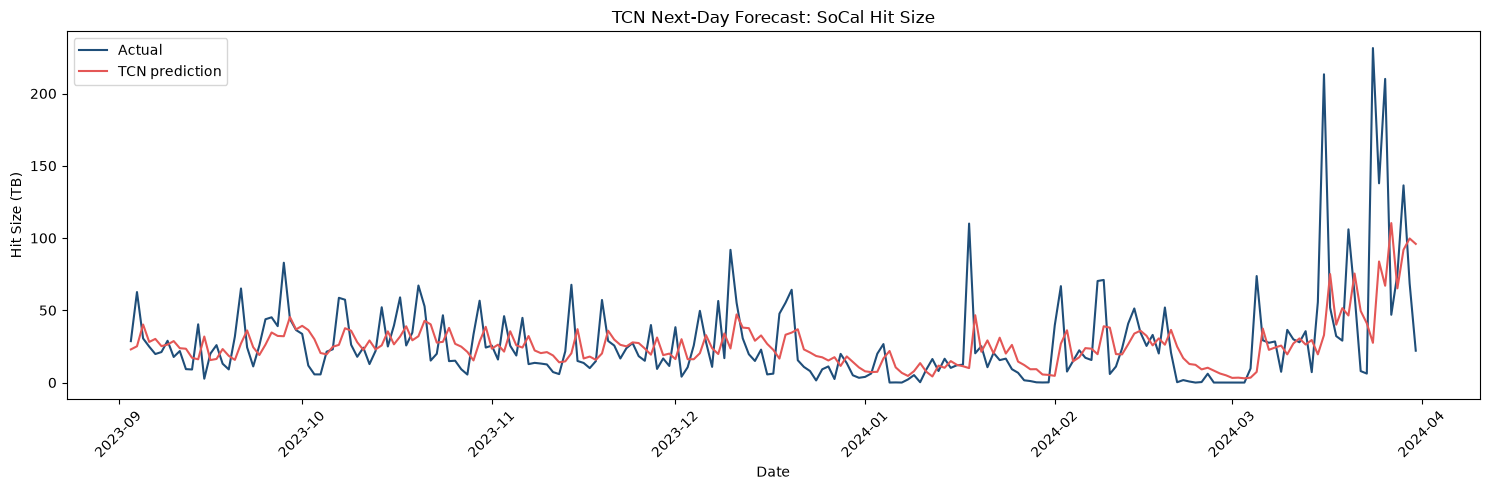

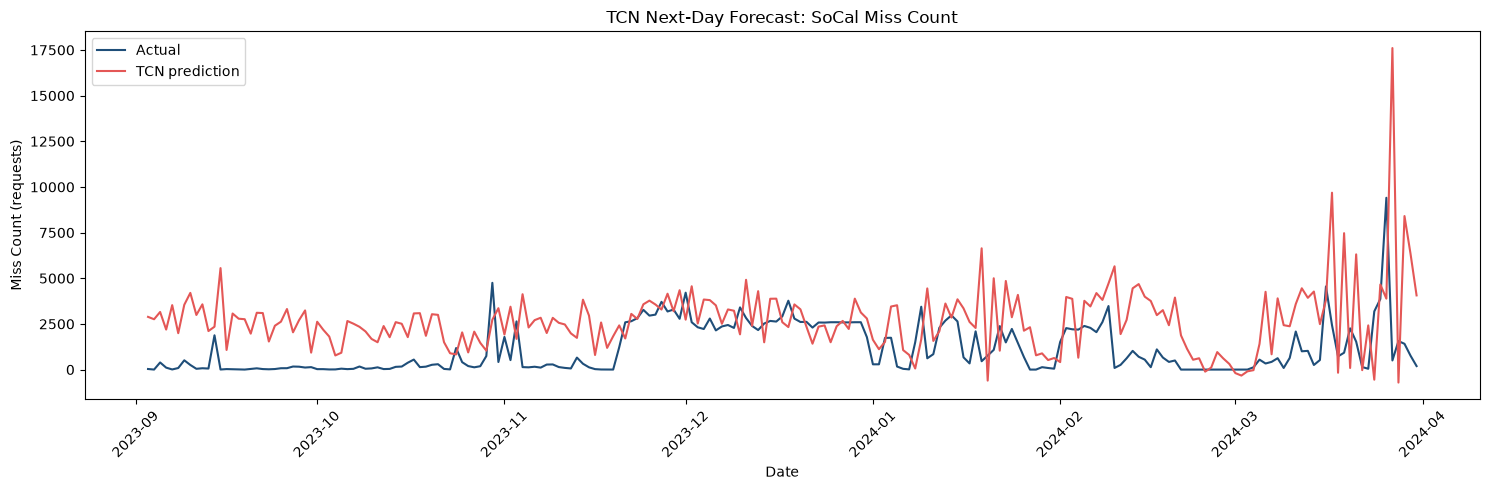

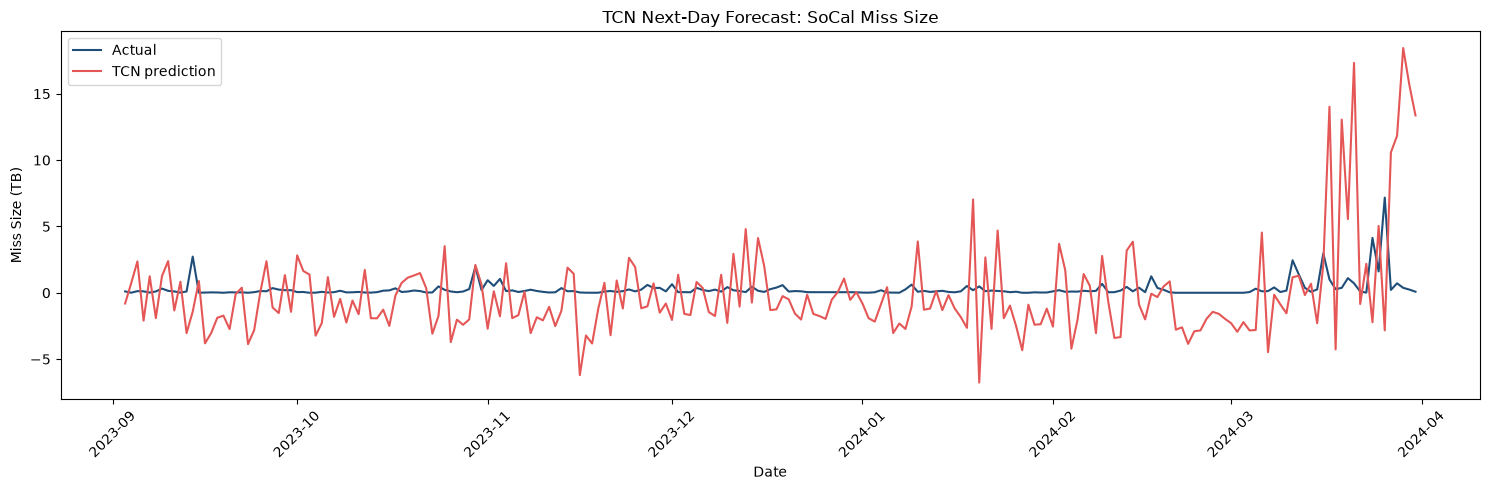

In [17]:
model.eval()
X_test_tensor = torch.tensor(X_test.transpose(0, 2, 1), dtype=torch.float32).to(device)
with torch.no_grad():
    # Use tolist() instead of Tensor.numpy() to avoid a PyTorch/NumPy binary compatibility issue.
    predicted_scaled = np.asarray(model(X_test_tensor).cpu().tolist(), dtype=np.float32)
predicted = scaler.inverse_transform(predicted_scaled.reshape(-1, len(feature_names))).reshape(predicted_scaled.shape)
actual = scaler.inverse_transform(y_test.reshape(-1, len(feature_names))).reshape(y_test.shape)

rmse = {name: mean_squared_error(actual[:, 0, i], predicted[:, 0, i]) ** 0.5
        for i, name in enumerate(feature_names)}
rmse_table = pd.DataFrame({'RMSE': pd.Series(rmse)})
rmse_table['Unit'] = ['requests' if 'count' in name else 'TB' for name in rmse_table.index]
display(rmse_table)

# One actual-versus-predicted plot for each of the six target variables.
for feature_index, plot_feature in enumerate(feature_names):
    plot_unit = 'requests' if 'count' in plot_feature else 'TB'
    feature_label = plot_feature.replace('_', ' ').title()
    plt.figure(figsize=(15, 5))
    plt.plot(test_dates, actual[:, 0, feature_index], label='Actual', color='#1F4E79')
    plt.plot(test_dates, predicted[:, 0, feature_index], label='TCN prediction', color='#E45756')
    plt.title(f'TCN Next-Day Forecast: SoCal {feature_label}')
    plt.xlabel('Date')
    plt.ylabel(f'{feature_label} ({plot_unit})')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Structured TCN: Predict Access Volume and Hit Ratios

This version predicts log access count, log access size, hit count ratio, and hit size ratio. It then reconstructs the six original variables, guaranteeing non-negative hit and miss values and both additive identities.


In [18]:
# Build four non-redundant target variables from the six original variables.
structured_names = ['log_access_count', 'log_access_size', 'hit_count_ratio', 'hit_size_ratio']
count_ratio = np.divide(df['hit_count'], df['access_count'], out=np.zeros(len(df)), where=df['access_count'] > 0)
size_ratio = np.divide(df['hit_size'], df['access_size'], out=np.zeros(len(df)), where=df['access_size'] > 0)
structured_values = np.column_stack([
    np.log1p(df['access_count']),
    np.log1p(df['access_size']),
    count_ratio,
    size_ratio
]).astype(np.float32)

# Standardize inputs, but keep ratio targets on their natural [0, 1] scale.
structured_input_scaler = StandardScaler().fit(structured_values[:train_end])
log_target_scaler = StandardScaler().fit(structured_values[:train_end, :2])
structured_inputs = structured_input_scaler.transform(structured_values)
structured_targets = np.column_stack([
    log_target_scaler.transform(structured_values[:, :2]),
    structured_values[:, 2:]
]).astype(np.float32)

X_structured_all, _, _ = make_windows(structured_inputs, df.index, LOOKBACK, HORIZON)
_, y_structured_all, _ = make_windows(structured_targets, df.index, LOOKBACK, HORIZON)
X_structured_train, y_structured_train = X_structured_all[train_mask], y_structured_all[train_mask]
X_structured_validation, y_structured_validation = X_structured_all[validation_mask], y_structured_all[validation_mask]
X_structured_test, y_structured_test = X_structured_all[test_mask], y_structured_all[test_mask]
print('Structured train:', X_structured_train.shape, y_structured_train.shape)
print('Structured test:', X_structured_test.shape, y_structured_test.shape)

Structured train: (952, 28, 4) (952, 1, 4)
Structured test: (211, 28, 4) (211, 1, 4)


In [ ]:
class StructuredTCN(TCNForecaster):
    def forward(self, x):
        raw_output = super().forward(x)
        # Sigmoid constrains both hit ratios to the valid range [0, 1].
        return torch.cat([raw_output[:, :, :2], torch.sigmoid(raw_output[:, :, 2:])], dim=2)

structured_model = StructuredTCN(4, 4, HORIZON).to(device)
structured_train_loader = to_loader(X_structured_train, y_structured_train, shuffle=True)
structured_validation_loader = to_loader(X_structured_validation, y_structured_validation)
structured_optimizer = torch.optim.Adam(structured_model.parameters(), lr=1e-3)

def structured_loss(prediction, target):
    log_loss = nn.functional.mse_loss(prediction[:, :, :2], target[:, :, :2])
    ratio_loss = nn.functional.mse_loss(prediction[:, :, 2:], target[:, :, 2:])
    return log_loss + 5 * ratio_loss

best_validation_loss, best_state, no_improvement = float('inf'), None, 0
structured_history = {'train': [], 'validation': []}
for epoch in range(1, MAX_EPOCHS + 1):
    structured_model.train() 
    train_losses = []
    for X_batch, y_batch in structured_train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        structured_optimizer.zero_grad()
        loss = structured_loss(structured_model(X_batch), y_batch)
        loss.backward()
        structured_optimizer.step()
        train_losses.append(loss.item())

    structured_model.eval()
    with torch.no_grad():
        validation_losses = [structured_loss(structured_model(X_batch.to(device)), y_batch.to(device)).item()
                             for X_batch, y_batch in structured_validation_loader]
    train_loss, validation_loss = np.mean(train_losses), np.mean(validation_losses)
    structured_history['train'].append(train_loss)
    structured_history['validation'].append(validation_loss)
    if validation_loss < best_validation_loss:
        best_validation_loss, best_state, no_improvement = validation_loss, copy.deepcopy(structured_model.state_dict()), 0
    else:
        no_improvement += 1
        if no_improvement >= PATIENCE:
            print(f'Early stopping at epoch {epoch}')
            break
    if epoch == 1 or epoch % 10 == 0:
        print(f'Epoch {epoch:02d}: train loss={train_loss:.4f}, validation loss={validation_loss:.4f}')

structured_model.load_state_dict(best_state)

Epoch 01: train loss=1.1638, validation loss=1.2732
Epoch 10: train loss=0.4677, validation loss=0.7485
Epoch 20: train loss=0.4163, validation loss=0.7394
Epoch 30: train loss=0.3664, validation loss=0.7387
Epoch 40: train loss=0.3085, validation loss=0.7524
Early stopping at epoch 41


<All keys matched successfully>

,Structured TCN RMSE,Unit
access_count,12550.459434,requests
access_size,32.760237,TB
hit_count,11973.431254,requests
hit_size,32.613927,TB
miss_count,1141.629482,requests
miss_size,1.914528,TB


Maximum access_count identity difference: 0.00097656


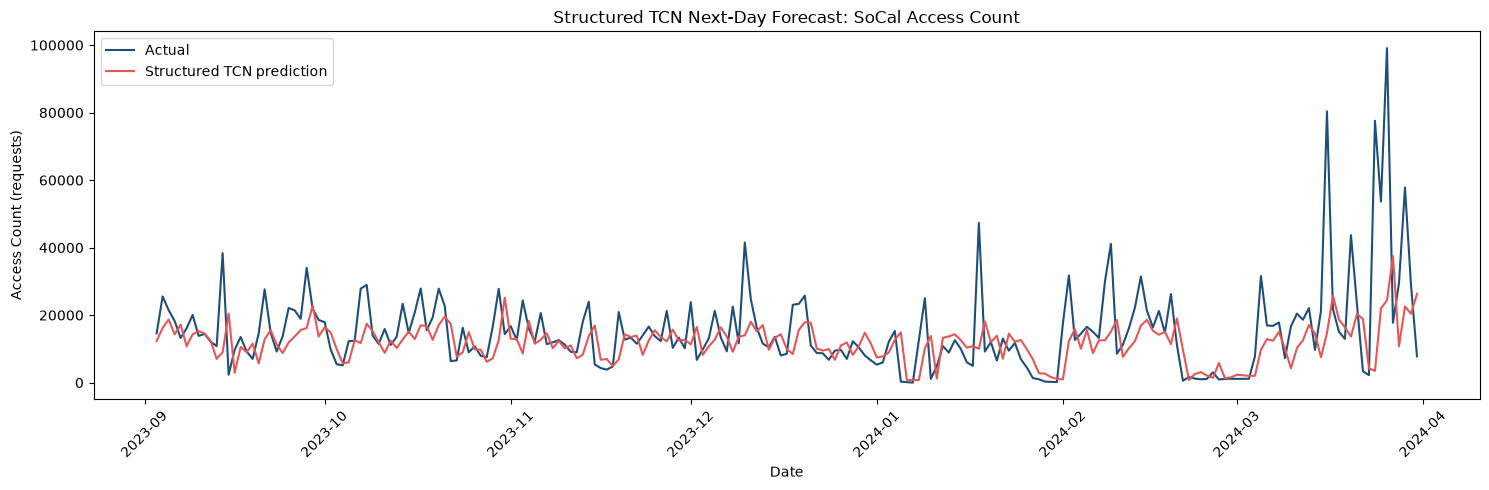

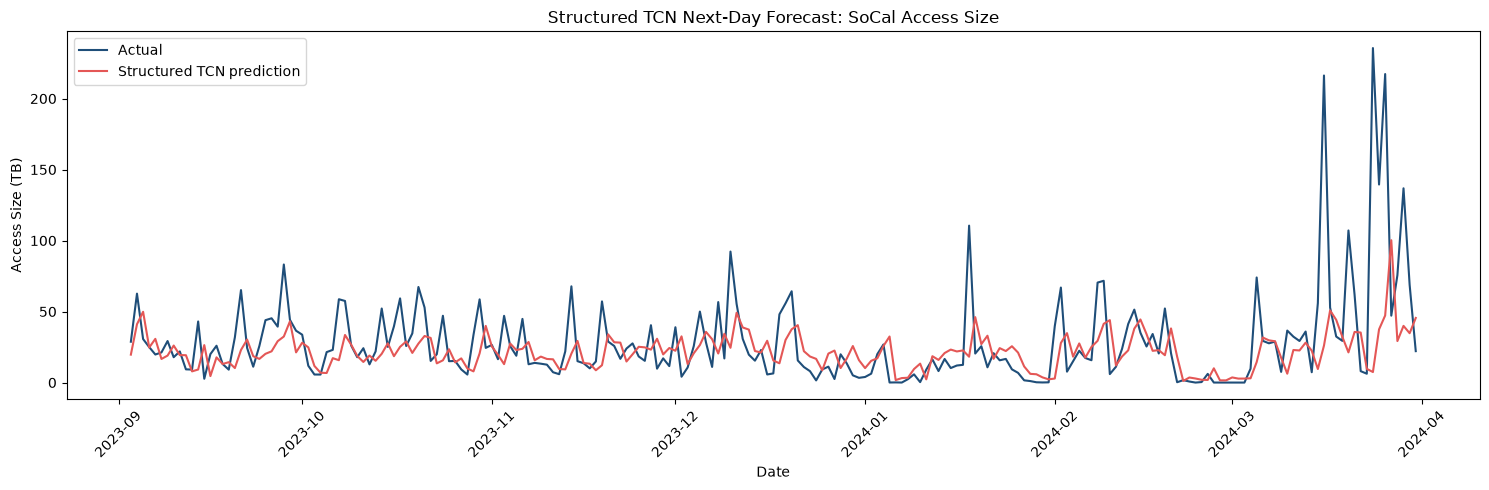

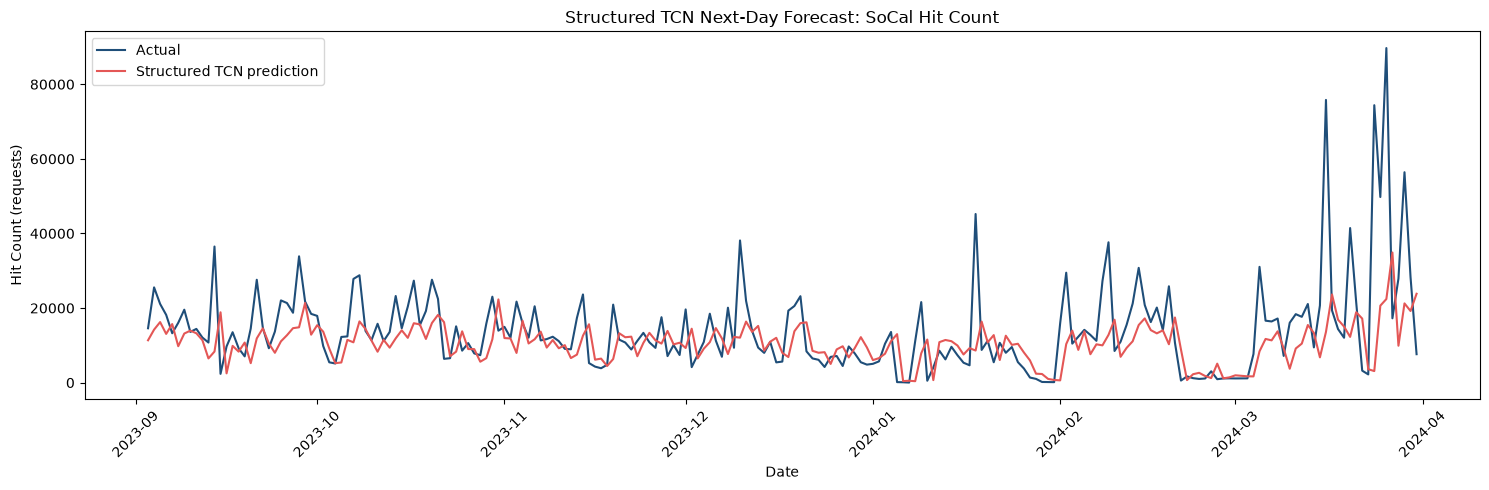

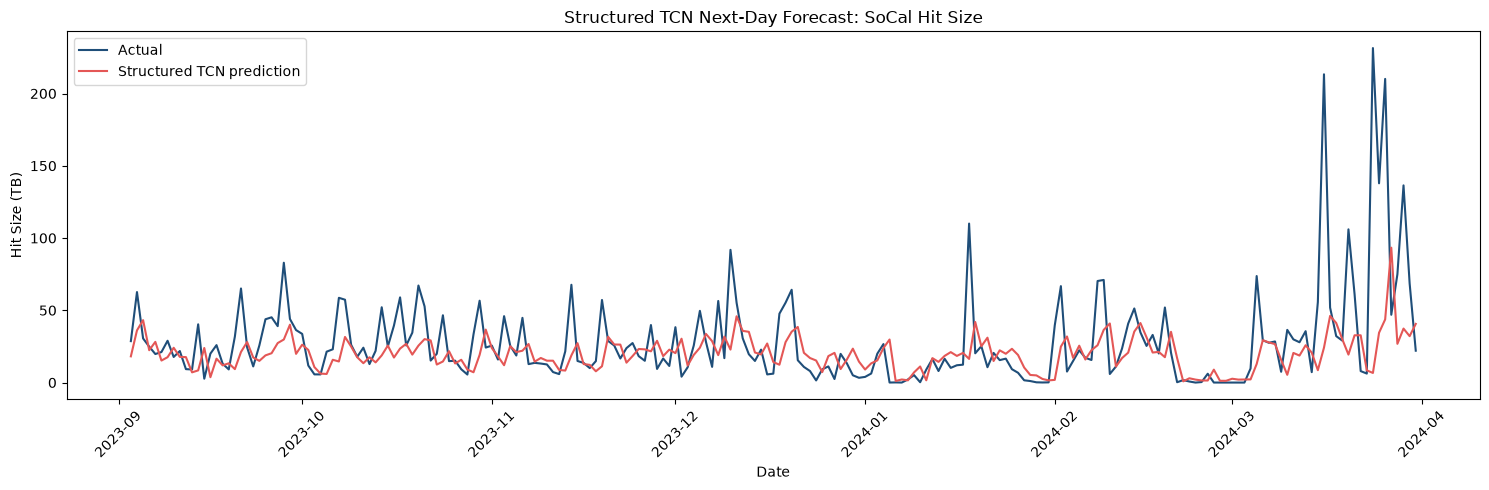

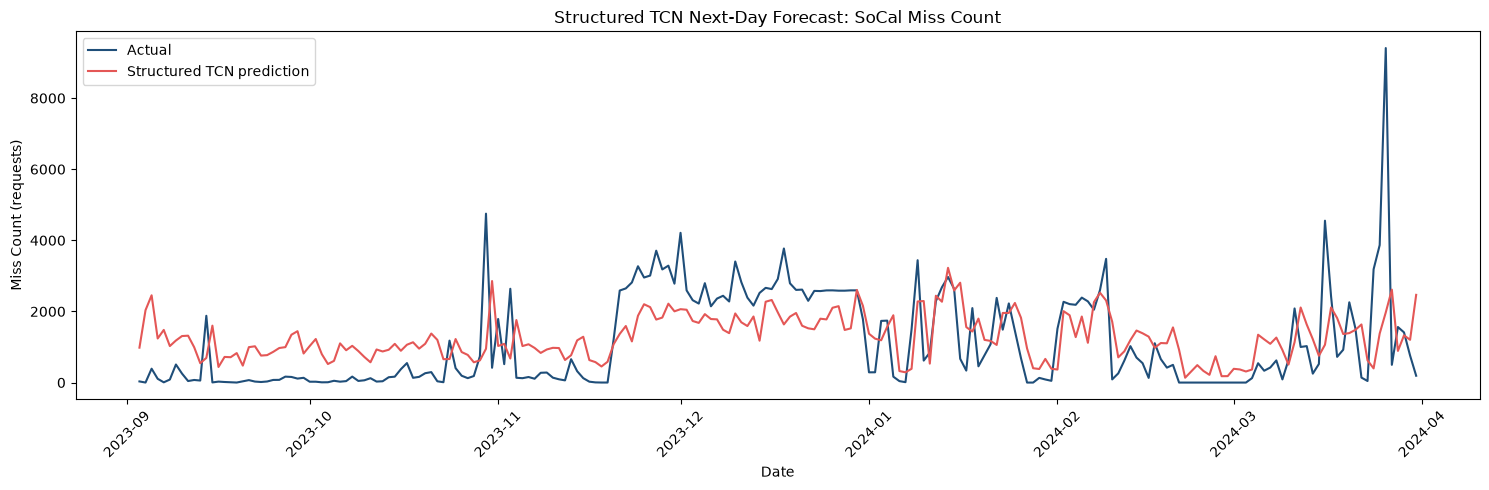

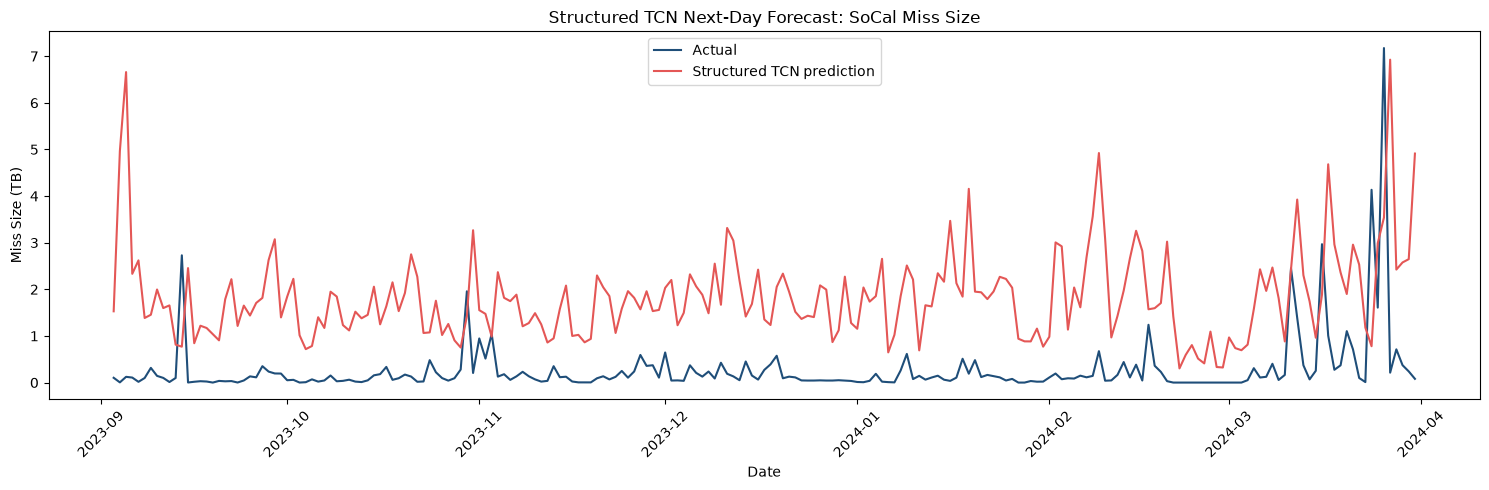

In [20]:
# Reconstruct six original variables and calculate RMSE in requests and TB.
structured_model.eval()
X_structured_test_tensor = torch.tensor(X_structured_test.transpose(0, 2, 1), dtype=torch.float32).to(device)
with torch.no_grad():
    structured_prediction = np.asarray(structured_model(X_structured_test_tensor).cpu().tolist(), dtype=np.float32)

predicted_logs = log_target_scaler.inverse_transform(structured_prediction[:, :, :2].reshape(-1, 2)).reshape(-1, HORIZON, 2)
predicted_access_count = np.expm1(predicted_logs[:, :, 0]).clip(min=0)
predicted_access_size = np.expm1(predicted_logs[:, :, 1]).clip(min=0)
predicted_count_ratio = np.clip(structured_prediction[:, :, 2], 0, 1)
predicted_size_ratio = np.clip(structured_prediction[:, :, 3], 0, 1)

structured_predicted = np.empty((len(X_structured_test), HORIZON, 6), dtype=np.float32)
structured_predicted[:, :, 0] = predicted_access_count
structured_predicted[:, :, 1] = predicted_access_size
structured_predicted[:, :, 2] = predicted_access_count * predicted_count_ratio
structured_predicted[:, :, 3] = predicted_access_size * predicted_size_ratio
structured_predicted[:, :, 4] = predicted_access_count * (1 - predicted_count_ratio)
structured_predicted[:, :, 5] = predicted_access_size * (1 - predicted_size_ratio)

structured_actual = values[target_positions[test_mask]][:, None, :]
structured_rmse = {name: mean_squared_error(structured_actual[:, 0, i], structured_predicted[:, 0, i]) ** 0.5
                   for i, name in enumerate(feature_names)}
structured_rmse_table = pd.DataFrame({'Structured TCN RMSE': pd.Series(structured_rmse)})
structured_rmse_table['Unit'] = ['requests' if 'count' in name else 'TB' for name in structured_rmse_table.index]
display(structured_rmse_table)

identity_check = np.max(np.abs(structured_predicted[:, :, 0] - structured_predicted[:, :, 2] - structured_predicted[:, :, 4]))
print(f'Maximum access_count identity difference: {identity_check:.8f}')

# One actual-versus-predicted plot for each of the six reconstructed variables.
for plot_index, plot_feature in enumerate(feature_names):
    plot_unit = 'requests' if 'count' in plot_feature else 'TB'
    feature_label = plot_feature.replace('_', ' ').title()
    plt.figure(figsize=(15, 5))
    plt.plot(test_dates, structured_actual[:, 0, plot_index], label='Actual', color='#1F4E79')
    plt.plot(test_dates, structured_predicted[:, 0, plot_index], label='Structured TCN prediction', color='#E45756')
    plt.title(f'Structured TCN Next-Day Forecast: SoCal {feature_label}')
    plt.xlabel('Date')
    plt.ylabel(f'{feature_label} ({plot_unit})')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Interpretation

The direct six-variable, one-step TCN baseline does not enforce the two additive XCache identities. The structured TCN above predicts non-redundant variables and reconstructs the six original variables.


### Next steps

1. Change different training and testing periods  
    maybe after the last changing point  
2. Add more features to help training  
    day of week  
    month  
    weekend indicator  
3. Direct TCN Hyperparameter Experiments  
    Compare regularized direct / structured TCN configurations on the same chronological split.   
